In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

In [2]:
import numpy as np
import pylab as plt
import glob
import os
from pprint import pprint
import scipy.integrate as inte
import scipy.special as special
import scipy.interpolate as interp
import scipy.signal as sig

In [3]:
import icewave.display.graphes as graphes
import icewave.phone.analyse as analyse
import icewave.tools.datafolders as df
import icewave.tools.rw_data as rw_data

#import sympy #symoblic python
#import mpmath as math
#import cv2
import glob
import csv
import os

import icewave.tools.rw_data as rw

macOS
MacBook-Air.local


In [4]:
datafolder = '/Users/stephane/Documents/CASCADE26/INSTRUMENTS/Chipiron/Data_Calibration/Calibration_20260105/'
filelist = glob.glob(datafolder + '*-Usb-*')
print(len(filelist))

22


/Users/stephane/Documents/CASCADE26/INSTRUMENTS/Chipiron/Data_Calibration/Calibration_20260105/P101_D2026-01-05T13_17_10-Usb-1-1035532070699--1.csv
/Users/stephane/Documents/CASCADE26/INSTRUMENTS/Chipiron/Data_Calibration/Calibration_20260105/P101_D2026-01-05T14_32_35-Usb-1-1040057433213--1.csv
/Users/stephane/Documents/CASCADE26/INSTRUMENTS/Chipiron/Data_Calibration/Calibration_20260105/P101_D2026-01-05T13_32_31-Usb-1-1036453618624--1.csv
/Users/stephane/Documents/CASCADE26/INSTRUMENTS/Chipiron/Data_Calibration/Calibration_20260105/P101_D2026-01-05T13_31_46-Usb-1-1036407979314--1.csv
/Users/stephane/Documents/CASCADE26/INSTRUMENTS/Chipiron/Data_Calibration/Calibration_20260105/P101_D2026-01-05T09_47_01-Usb-1-1022923290213--1.csv
/Users/stephane/Documents/CASCADE26/INSTRUMENTS/Chipiron/Data_Calibration/Calibration_20260105/P101_D2026-01-05T14_05_31-Usb-1-1038433586435--1.csv
/Users/stephane/Documents/CASCADE26/INSTRUMENTS/Chipiron/Data_Calibration/Calibration_20260105/P101_D2026-01-05T

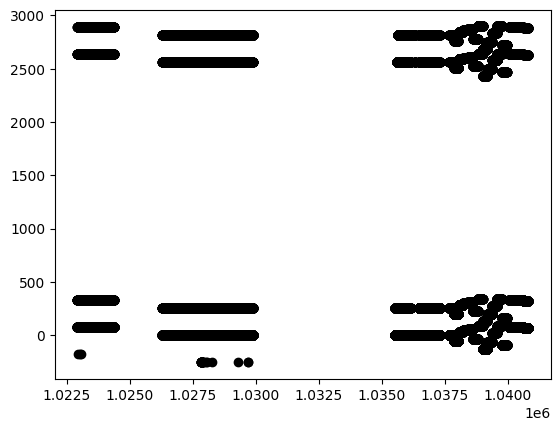

In [41]:

def read_usb(raw):
    tf,tall,val = [],[],[]
    
    for i,line in enumerate(raw):
        tall.append(int(line[0]))
        #tf.append(int(line[0]))
        if i==0:        
            buffer = int(line[1])
        else:
            tbuf = int(line[0])
            if tbuf==-1:
                continue
            if np.abs((tbuf-tall[-1])-5000)<10000:
                part2 = "{0:b}".format(int(line[1]))
                #print(part2)
                
                val.append(buffer+int(part2[-2:])*2**8)
                tf.append(int(line[0]))
            else:
                buffer = int(line[1])

    tf = np.asarray(tf)/10**6 #conversion in seconds
    val = np.asarray(val)
    return tf,val

for filename in filelist:
    print(filename)
    raw = rw.read_csv(filename,delimiter=',')

    t,val = read_usb(raw)
    plt.plot(t,val,'ko')

array([ 1.03881608e+06,  1.03881612e+06,  1.03881613e+06, ...,
       -1.00000000e-06, -1.00000000e-06, -1.00000000e-06], shape=(179999,))

[['2342932427161', ' -43', ' '],
 ['2342932476195', ' -104', ' '],
 ['2342932677195', ' -44', ' '],
 ['2342932726193', ' -104', ' '],
 ['2342932926688', ' -43', ' '],
 ['2342932980133', ' -108', ' '],
 ['2342933180650', ' -44', ' '],
 ['2342933229993', ' -105', ' '],
 ['2342933430611', ' -43', ' '],
 ['2342933479823', ' -104', ' '],
 ['2342933680586', ' -44', ' '],
 ['2342933729677', ' -107', ' '],
 ['2342933930441', ' -44', ' '],
 ['2342933979518', ' -103', ' '],
 ['2342934180186', ' -45', ' '],
 ['2342934229355', ' -103', ' '],
 ['2342934429965', ' -44', ' '],
 ['2342934479132', ' -101', ' '],
 ['2342934679909', ' -44', ' '],
 ['2342934733172', ' -104', ' '],
 ['2342934933676', ' -43', ' '],
 ['2342934982840', ' -106', ' '],
 ['2342935183577', ' -43', ' '],
 ['2342935232840', ' -104', ' '],
 ['2342935433399', ' -44', ' '],
 ['2342935482538', ' -104', ' '],
 ['2342935683198', ' -43', ' '],
 ['2342935732549', ' -105', ' '],
 ['2342935933048', ' -44', ' '],
 ['2342935982249', ' -105', '